In [74]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

In [37]:
TARGET_COL = 'target'

In [38]:
iris = load_iris(as_frame=True)
df = iris.frame

In [39]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [40]:
print(f"The shape of df : {df.shape}")
print('-'*25)
print(f"The data type of each column : {df.dtypes}")
print('-'*25)
print(f"The number of missing values per column : {df.isnull().sum()}")
print('-'*25)
print(f"Duplicate rows : {df.duplicated().sum()}")
print('-'*25)
print(f"How many rows each target class : {df[TARGET_COL].value_counts()}")

The shape of df : (150, 5)
-------------------------
The data type of each column : sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
dtype: object
-------------------------
The number of missing values per column : sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64
-------------------------
Duplicate rows : 1
-------------------------
How many rows each target class : target
0    50
1    50
2    50
Name: count, dtype: int64


In [41]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [42]:
dup = df[df.duplicated(keep=False)]
dup

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
101,5.8,2.7,5.1,1.9,2
142,5.8,2.7,5.1,1.9,2


In [43]:
dup.index.tolist()

[101, 142]

In [44]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [45]:
df[TARGET_COL].unique()

array([0, 1, 2])

## Remove duplicates BEFORE splitting

In [46]:
df = df.drop_duplicates()

In [47]:
df.duplicated().sum()

np.int64(0)

In [48]:
df.shape

(149, 5)

In [49]:
X = df.drop(columns=TARGET_COL)
y = df[TARGET_COL]

In [50]:
X.duplicated().sum()

np.int64(0)

In [51]:
print(df[TARGET_COL].value_counts())

target
0    50
1    50
2    49
Name: count, dtype: int64


In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [53]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((119, 4), (30, 4), (119,), (30,))

In [54]:
y_train.value_counts(), y_test.value_counts()

(target
 0    40
 1    40
 2    39
 Name: count, dtype: int64,
 target
 1    10
 2    10
 0    10
 Name: count, dtype: int64)

In [55]:
print(y_train.value_counts(normalize=True).round(2))
print('-'*25)
print(y_test.value_counts(normalize=True).round(2))

target
0    0.34
1    0.34
2    0.33
Name: proportion, dtype: float64
-------------------------
target
1    0.33
2    0.33
0    0.33
Name: proportion, dtype: float64


### EDA on the training set

In [56]:
train_df = X_train.copy()
train_df[TARGET_COL] = y_train
train_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
6,4.6,3.4,1.4,0.3,0
128,6.4,2.8,5.6,2.1,2
95,5.7,3.0,4.2,1.2,1
44,5.1,3.8,1.9,0.4,0
30,4.8,3.1,1.6,0.2,0


In [57]:
train_df["species"] = train_df[TARGET_COL].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
train_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
6,4.6,3.4,1.4,0.3,0,setosa
128,6.4,2.8,5.6,2.1,2,virginica
95,5.7,3.0,4.2,1.2,1,versicolor
44,5.1,3.8,1.9,0.4,0,setosa
30,4.8,3.1,1.6,0.2,0,setosa


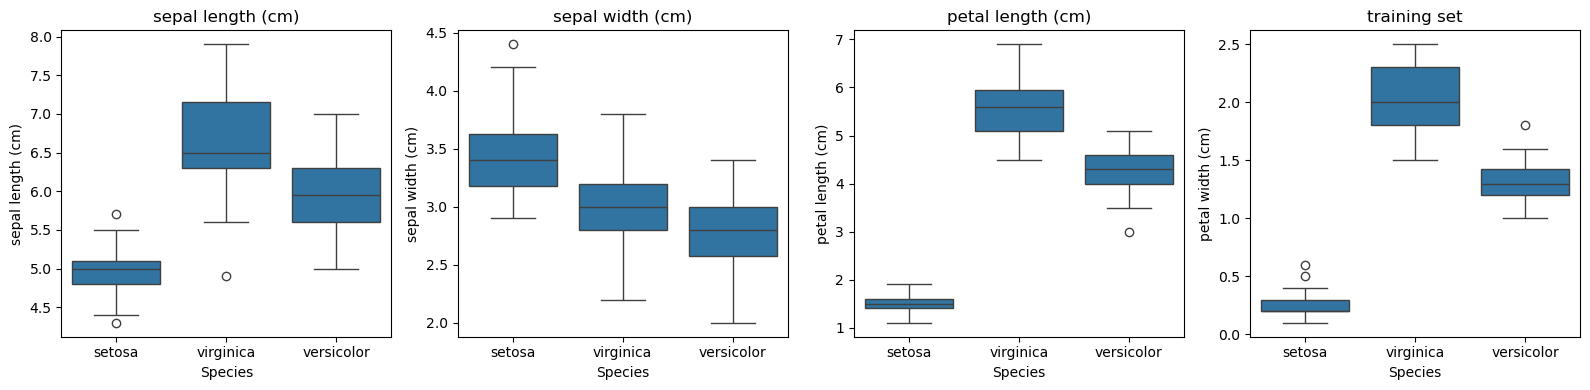

In [65]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, X_train.columns):
    sns.boxplot(data=train_df, x='species', y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Species")
    ax.set_ylabel(col)
plt.title("training set")
plt.tight_layout()
plt.show()

In [61]:
print(train_df.shape)

(119, 6)


## Correlation heatmap

In [68]:
corr = X_train.corr()
corr.round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.00,-0.15,0.88,0.82
sepal width (cm),-0.15,1.00,-0.43,-0.36
petal length (cm),0.88,-0.43,1.00,0.96
petal width (cm),0.82,-0.36,0.96,1.00


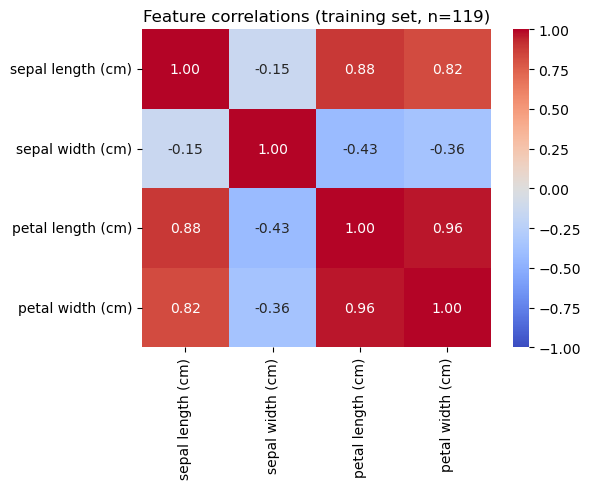

In [72]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Feature correlations (training set, n=119)")
plt.tight_layout()
plt.show()

## Preprocessing in a Pipeline

In [76]:
nums_cols = X_train.columns.to_list()
nums_cols

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [77]:
preprocessor = ColumnTransformer([
    ('scale', StandardScaler(), nums_cols)
])

In [78]:
preprocessor

ColumnTransformer(transformers=[('scale', StandardScaler(),
                                 ['sepal length (cm)', 'sepal width (cm)',
                                  'petal length (cm)', 'petal width (cm)'])])

In [90]:
X_train_scaled = preprocessor.fit_transform(X_train)
pd.DataFrame(X_train_scaled).head()

,0,1,2,3
0,-1.501587,0.769031,-1.339093,-1.179737
1,0.639824,-0.586742,1.041834,1.186365
2,-0.192947,-0.134818,0.248192,0.003314
3,-0.906751,1.672881,-1.055649,-1.048287
4,-1.263653,0.091144,-1.225715,-1.311187


In [85]:
X_test_scaled = preprocessor.transform(X_test)
pd.DataFrame(X_test_scaled).head()

,0,1,2,3
0,-0.311914,-1.264629,0.078126,-0.128136
1,-0.311914,-0.134818,0.418258,0.397664
2,1.234661,0.091144,0.758390,1.449265
3,-1.025718,0.769031,-1.282404,-1.311187
4,0.758791,-0.134818,0.815079,1.054914


In [86]:
X_train_scaled.shape, X_test_scaled.shape

((119, 4), (30, 4))

In [88]:
X_train_scaled.mean(axis=0).round(2) , X_train_scaled.std(axis=0).round(2)

(array([-0.,  0.,  0.,  0.]), array([1., 1., 1., 1.]))

In [89]:
X_test_scaled.mean(axis=0).round(2), X_test_scaled.std(axis=0).round(2)

(array([-0.11,  0.  , -0.04, -0.02]), array([0.92, 0.91, 0.99, 1.  ]))